In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn -q


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style("whitegrid")
sns.set_context("notebook")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:

# Set random seed for reproducibility
np.random.seed(42)

# Number of customers
n = 500

# Customers in each underlying profile
customers_per_group = 100

# Generate customer data
data = []

# Profile 1: Low income, high spending
for i in range(customers_per_group):
    data.append([
        np.random.choice(['Male', 'Female']),
        np.random.randint(18, 40),
        np.random.normal(25, 7),
        np.random.normal(80, 8)
    ])

# Profile 2: High income, high spending
for i in range(customers_per_group):
    data.append([
        np.random.choice(['Male', 'Female']),
        np.random.randint(25, 50),
        np.random.normal(80, 10),
        np.random.normal(80, 8)
    ])

# Profile 3: Medium income, medium spending
for i in range(customers_per_group):
    data.append([
        np.random.choice(['Male', 'Female']),
        np.random.randint(25, 55),
        np.random.normal(50, 8),
        np.random.normal(50, 10)
    ])

# Profile 4: High income, low spending
for i in range(customers_per_group):
    data.append([
        np.random.choice(['Male', 'Female']),
        np.random.randint(35, 65),
        np.random.normal(85, 10),
        np.random.normal(20, 8)
    ])

# Profile 5: Low income, low spending
for i in range(customers_per_group):
    data.append([
        np.random.choice(['Male', 'Female']),
        np.random.randint(18, 45),
        np.random.normal(25, 7),
        np.random.normal(20, 8)
    ])

# Create DataFrame
df = pd.DataFrame(
    data,
    columns=[
        'Gender',
        'Age',
        'Annual Income (k$)',
        'Spending Score (1-100)'
    ]
)

# Add unique Customer IDs
df.insert(0, 'CustomerID', range(1, n+1))

# Keep values within realistic ranges
df['Annual Income (k$)'] = df['Annual Income (k$)'].clip(10, 137).round(2)
df['Spending Score (1-100)'] = df['Spending Score (1-100)'].clip(1, 100).round(2)

# Display dataset
print("Synthetic Mall Customer Dataset Generated!")
print("Dataset Shape:", df.shape)

display(df.head(10))


Synthetic Mall Customer Dataset Generated!
Dataset Shape: (500, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,37,17.22,82.55
1,2,Male,28,10.92,76.06
2,3,Female,20,21.71,84.34
3,4,Female,38,35.24,92.31
4,5,Male,29,25.16,76.58
5,6,Male,27,23.24,78.69
6,7,Female,36,26.00,79.72
7,8,Male,20,27.92,86.66
8,9,Male,24,10.81,88.96
9,10,Female,38,19.76,73.77


In [4]:

# Dataset information
print("Dataset Information:")
df.info()

# Statistical description
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CustomerID              500 non-null    int64  
 1   Gender                  500 non-null    object 
 2   Age                     500 non-null    int64  
 3   Annual Income (k$)      500 non-null    float64
 4   Spending Score (1-100)  500 non-null    float64
dtypes: float64(2), int64(2), object(1)
memory usage: 19.7+ KB

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,500.000000,500.000000,500.000000,500.000000
mean,250.500000,36.600000,53.094040,50.768020
std,144.481833,11.347667,27.637467,28.348827
min,1.000000,18.000000,10.000000,1.000000
25%,125.750000,28.000000,26.880000,23.292500
50%,250.500000,36.000000,49.825000,51.670000
75%,375.250000,44.250000,79.917500,77.597500
max,500.000000,64.000000,109.720000,100.000000



Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0


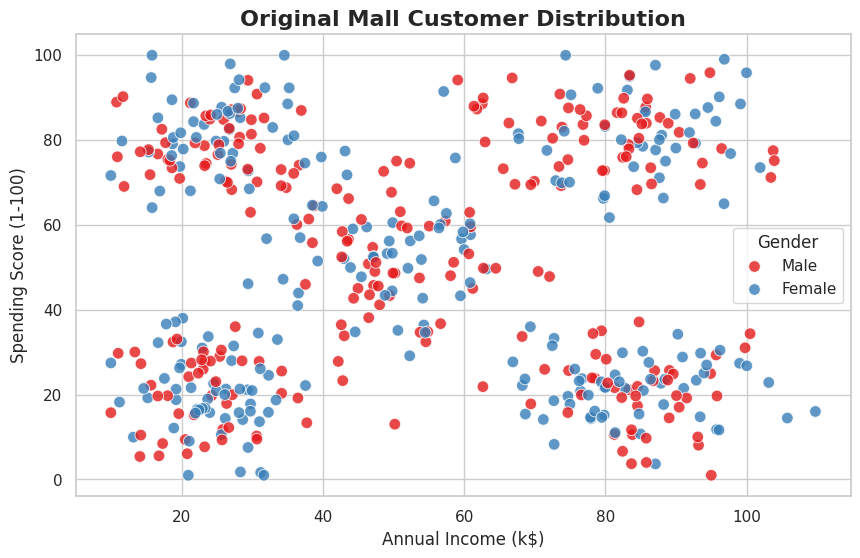

In [5]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    palette='Set1',
    s=70,
    alpha=0.8
)

plt.title(
    'Original Mall Customer Distribution',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

plt.legend(title='Gender')
plt.show()


In [6]:

# Select numerical features
X = df[
    ['Annual Income (k$)', 'Spending Score (1-100)']
]

print("Selected Features:")
display(X.head())


Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,17.22,82.55
1,10.92,76.06
2,21.71,84.34
3,35.24,92.31
4,25.16,76.58


In [7]:

# Initialize scaler
scaler = StandardScaler()

# Transform features
X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")

print("\nScaled Data:")
print(X_scaled[:5])


Feature scaling completed!

Scaled Data:
[[-1.29932198  1.12222665]
 [-1.5275017   0.89306374]
 [-1.13669865  1.18543183]
 [-0.64665554  1.46685377]
 [-1.01174309  0.91142502]]


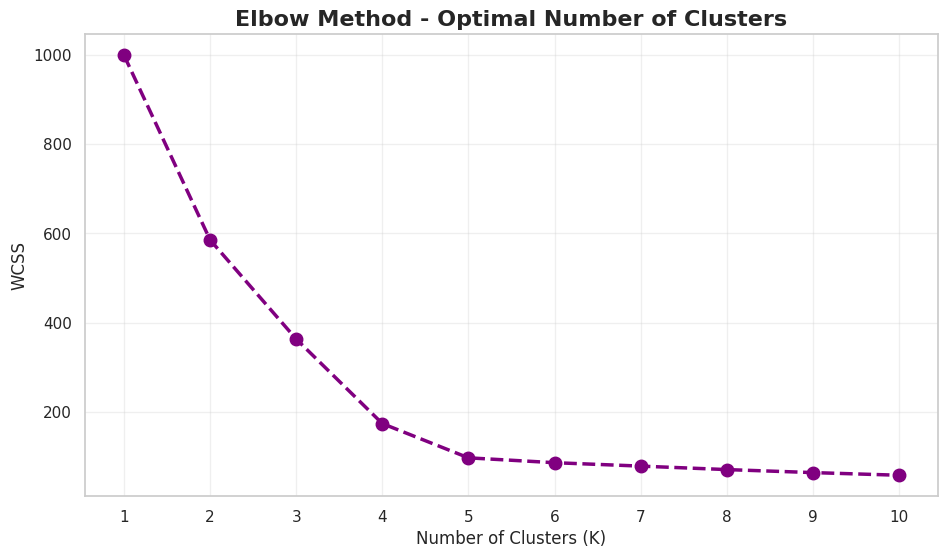

In [8]:

# Store WCSS values
wcss = []

# Test K values from 1 to 10
for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


# Plot Elbow Graph
plt.figure(figsize=(11, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    linestyle='--',
    color='purple',
    linewidth=2.5,
    markersize=9
)

plt.title(
    'Elbow Method - Optimal Number of Clusters',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('WCSS', fontsize=12)

plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)

plt.show()


In [9]:

# Set optimal K based on Elbow graph
optimal_k = 5

# Create K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")

# Display results
display(df.head(10))

# Count customers in each cluster
print("\nCustomers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())


K-Means Clustering Completed!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,37,17.22,82.55,2
1,2,Male,28,10.92,76.06,2
2,3,Female,20,21.71,84.34,2
3,4,Female,38,35.24,92.31,2
4,5,Male,29,25.16,76.58,2
5,6,Male,27,23.24,78.69,2
6,7,Female,36,26.00,79.72,2
7,8,Male,20,27.92,86.66,2
8,9,Male,24,10.81,88.96,2
9,10,Female,38,19.76,73.77,2



Customers in Each Cluster:
Cluster
0    101
1     97
2     99
3    101
4    102
Name: count, dtype: int64


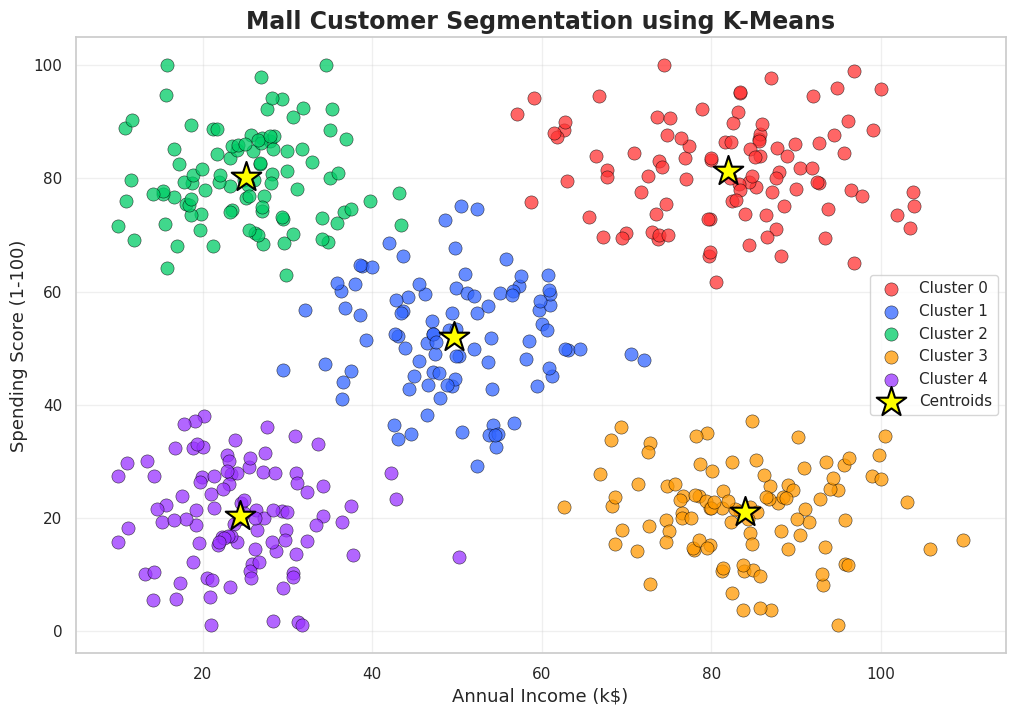

In [10]:

# Convert centroids back to original scale
centroids = scaler.inverse_transform(
    kmeans.cluster_centers_
)

# Define colors
colors = [
    '#FF3333',
    '#3366FF',
    '#00CC66',
    '#FF9900',
    '#9933FF'
]

plt.figure(figsize=(12, 8))

# Plot each cluster
for i in range(optimal_k):

    cluster_data = df[df['Cluster'] == i]

    plt.scatter(
        cluster_data['Annual Income (k$)'],
        cluster_data['Spending Score (1-100)'],
        color=colors[i],
        label=f'Cluster {i}',
        s=90,
        alpha=0.75,
        edgecolor='black',
        linewidth=0.4
    )

# Plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color='yellow',
    marker='*',
    s=500,
    edgecolor='black',
    linewidth=1.5,
    label='Centroids'
)

plt.title(
    'Mall Customer Segmentation using K-Means',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Annual Income (k$)', fontsize=13)
plt.ylabel('Spending Score (1-100)', fontsize=13)

plt.legend(fontsize=11)
plt.grid(alpha=0.3)

plt.show()


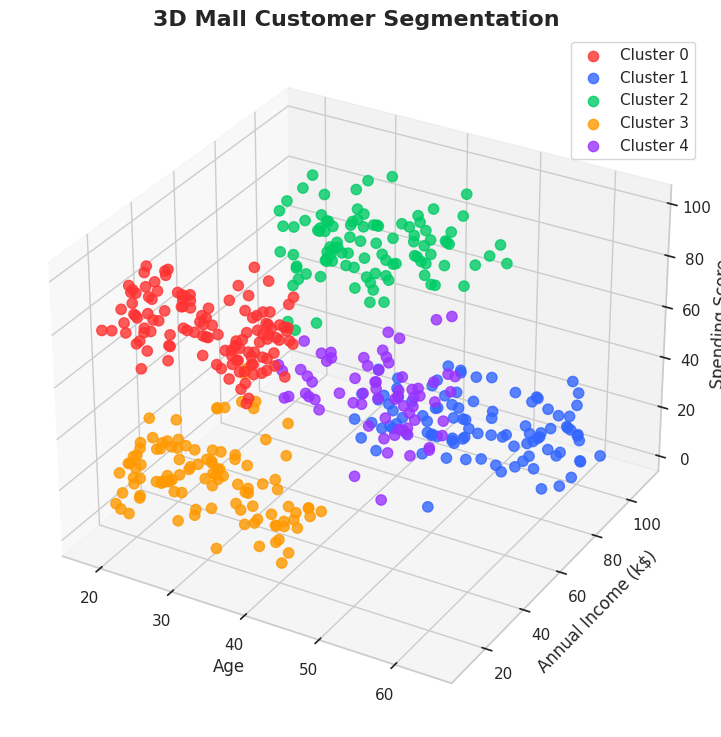

In [11]:

# Select three features
X_3d = df[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
]

# Scale three features
scaler_3d = StandardScaler()
X_3d_scaled = scaler_3d.fit_transform(X_3d)

# Apply K-Means
kmeans_3d = KMeans(
    n_clusters=5,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Cluster_3D'] = kmeans_3d.fit_predict(X_3d_scaled)

# Create 3D figure
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

colors = [
    '#FF3333',
    '#3366FF',
    '#00CC66',
    '#FF9900',
    '#9933FF'
]

# Plot clusters
for i in range(5):

    cluster_data = df[df['Cluster_3D'] == i]

    ax.scatter(
        cluster_data['Age'],
        cluster_data['Annual Income (k$)'],
        cluster_data['Spending Score (1-100)'],
        color=colors[i],
        label=f'Cluster {i}',
        s=55,
        alpha=0.8
    )

# Titles and labels
ax.set_title(
    '3D Mall Customer Segmentation',
    fontsize=16,
    fontweight='bold'
)

ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score')

ax.legend()

plt.show()


In [12]:

# Calculate cluster averages
cluster_analysis = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2)

print("Customer Cluster Analysis:")
display(cluster_analysis)

# Number of customers per cluster
print("\nCluster Sizes:")
display(df['Cluster'].value_counts().sort_index())


Customer Cluster Analysis:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,35.95,81.92,81.28
1,38.92,49.69,51.99
2,28.27,25.13,80.18
3,50.21,83.98,21.01
4,29.65,24.35,20.31



Cluster Sizes:


,count
Cluster,
0,101
1,97
2,99
3,101
4,102


In [13]:

for cluster, row in cluster_analysis.iterrows():

    income = row['Annual Income (k$)']
    spending = row['Spending Score (1-100)']

    if income >= 60 and spending >= 60:
        segment = "High Income - High Spending"

    elif income >= 60 and spending < 40:
        segment = "High Income - Low Spending"

    elif income < 40 and spending >= 60:
        segment = "Low Income - High Spending"

    elif income < 40 and spending < 40:
        segment = "Low Income - Low Spending"

    else:
        segment = "Medium Income - Medium Spending"

    print(f"Cluster {cluster}: {segment}")


Cluster 0: High Income - High Spending
Cluster 1: Medium Income - Medium Spending
Cluster 2: Low Income - High Spending
Cluster 3: High Income - Low Spending
Cluster 4: Low Income - Low Spending


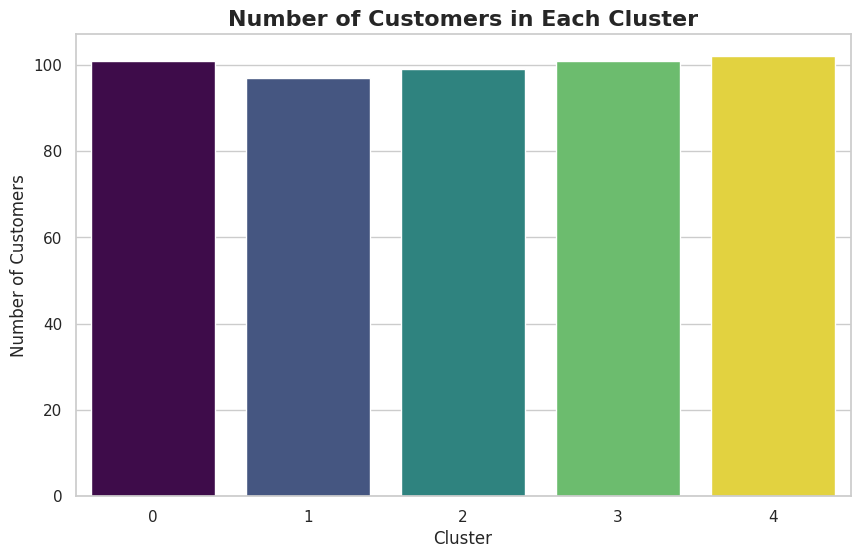

In [14]:

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='Cluster',
    hue='Cluster',
    palette='viridis',
    legend=False
)

plt.title(
    'Number of Customers in Each Cluster',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Cluster')
plt.ylabel('Number of Customers')

plt.show()


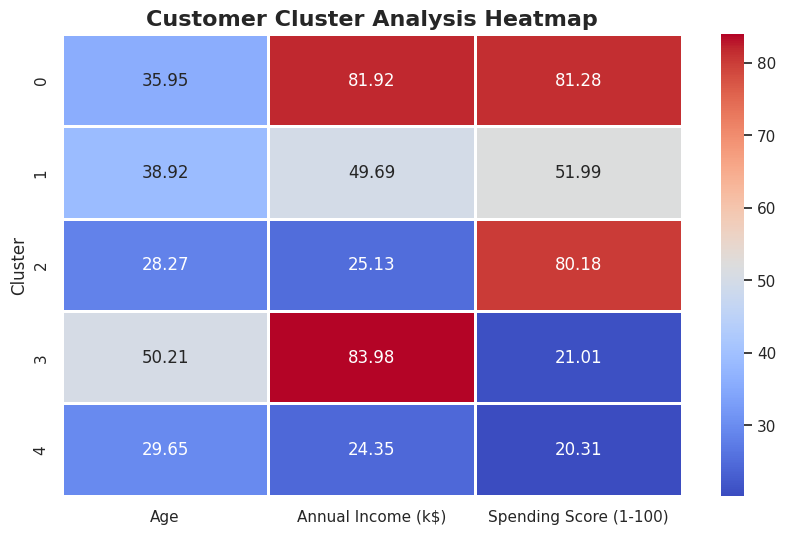

In [15]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_analysis,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=1,
    cbar=True
)

plt.title(
    'Customer Cluster Analysis Heatmap',
    fontsize=16,
    fontweight='bold'
)

plt.show()
